# ĐỒ ÁN MACHINE LEARNING: DỰ BÁO LƯỢT XEM SẢN PHẨM THEO NGÀY
**Tập dữ liệu:** Clickstream E-Shop Clothing 2008 (UCI Repository)

**Trình tự làm bài của nhóm:**
1. Đọc dữ liệu & khám phá sơ bộ
2. Kiểm tra chất lượng & làm sạch dữ liệu
3. Vì sao không dự đoán `price2` như nhiều bài trên mạng → chọn bài toán của nhóm
4. Xây bảng (sản phẩm × ngày), khám phá biến mục tiêu, tạo đặc trưng từ quá khứ
5. Mã hóa One-Hot & chia Train / Validation / Test theo thời gian
6. Baseline và các mô hình hồi quy (Linear Regression, Ridge, KNN, Decision Tree, Random Forest) — chọn siêu tham số trên Validation
7. Huấn luyện lại & đánh giá một lần trên Test
8. Phân tích kết quả
9. Góc nhìn khác: đặt bài toán dạng phân loại (Logistic Regression, Naive Bayes, KNN, Decision Tree, Random Forest)
10. Kết luận

---
## PHẦN 1: ĐỌC DỮ LIỆU & KHÁM PHÁ SƠ BỘ
Đầu tiên, nhóm nạp dữ liệu từ file CSV và xem 5 dòng đầu tiên để nắm cấu trúc bảng.

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (9, 4)      # kích thước mặc định của biểu đồ

# Trên Google Colab: bỏ dấu # ở 2 dòng dưới để tải file CSV lên trước
# from google.colab import files
# files.upload()

# Đọc file dữ liệu (các cột ngăn cách nhau bởi dấu chấm phẩy ';')
df = pd.read_csv('../data/e-shop_clothing_2008.csv', sep=';')
df.head()

,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


**Nhận xét 1:** Tên gốc của một số cột khá dài (như `page 1 (main category)`, `page 2 (clothing model)`). Nhóm đổi lại tên cột ngắn gọn (giữ đúng thứ tự cột gốc) và dùng `df.info()` để kiểm tra kiểu dữ liệu.

In [53]:
df.columns = ['year', 'month', 'day', 'order', 'country', 'session',
              'category', 'product', 'colour', 'location', 'photo', 'price', 'price2', 'page']

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165474 entries, 0 to 165473
Data columns (total 14 columns):
 #   Column    Non-Null Count   Dtype 
---  ------    --------------   ----- 
 0   year      165474 non-null  int64 
 1   month     165474 non-null  int64 
 2   day       165474 non-null  int64 
 3   order     165474 non-null  int64 
 4   country   165474 non-null  int64 
 5   session   165474 non-null  int64 
 6   category  165474 non-null  int64 
 7   product   165474 non-null  object
 8   colour    165474 non-null  int64 
 9   location  165474 non-null  int64 
 10  photo     165474 non-null  int64 
 11  price     165474 non-null  int64 
 12  price2    165474 non-null  int64 
 13  page      165474 non-null  int64 
dtypes: int64(13), object(1)
memory usage: 17.7+ MB


**Nhận xét 2:** Bảng gồm 165.474 dòng và 14 cột. Chỉ cột `product` là chữ (mã sản phẩm như `A13`), các cột còn lại là số nguyên. Tiếp theo, nhóm kiểm tra giá trị bị thiếu (`isnull`) và dòng bị trùng lặp hoàn toàn (`duplicated`).

In [54]:
print('Số giá trị bị thiếu (NaN) ở từng cột:')
print(df.isnull().sum())

print('\nSố dòng bị trùng lặp hoàn toàn:', df.duplicated().sum())

Số giá trị bị thiếu (NaN) ở từng cột:
year        0
month       0
day         0
order       0
country     0
session     0
category    0
product     0
colour      0
location    0
photo       0
price       0
price2      0
page        0
dtype: int64

Số dòng bị trùng lặp hoàn toàn: 0


**Nhận xét 3:** Không có giá trị bị thiếu và không có dòng trùng. Nhóm dùng `df.describe()` để xem phân phối thống kê của các biến số.

In [55]:
df.describe()

,year,month,day,order,country,session,category,colour,location,photo,price,price2,page
count,165474.0,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000
mean,2008.0,5.585887,14.524554,9.817476,26.952621,12058.417056,2.400842,6.227655,3.258198,1.260071,43.802507,1.488167,1.710166
std,0.0,1.328160,8.830374,13.478411,7.150691,7008.418903,1.144420,4.235606,1.713206,0.438674,12.548131,0.499861,0.982412
min,2008.0,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,18.000000,1.000000,1.000000
25%,2008.0,4.000000,7.000000,2.000000,29.000000,5931.000000,1.000000,3.000000,2.000000,1.000000,33.000000,1.000000,1.000000
50%,2008.0,5.000000,14.000000,6.000000,29.000000,11967.500000,2.000000,4.000000,3.000000,1.000000,43.000000,1.000000,1.000000
75%,2008.0,7.000000,22.000000,12.000000,29.000000,18219.000000,3.000000,9.000000,5.000000,2.000000,52.000000,2.000000,2.000000
max,2008.0,8.000000,31.000000,195.000000,47.000000,24026.000000,4.000000,14.000000,6.000000,2.000000,82.000000,2.000000,5.000000


**Câu hỏi quan trọng: một dòng dữ liệu thể hiện điều gì?** Nhóm xem thử toàn bộ các dòng của phiên truy cập (session) số 1.

In [56]:
print('Số sản phẩm khác nhau     :', df['product'].nunique())
print('Số phiên truy cập (session):', df['session'].nunique())

df[df['session'] == 1]

Số sản phẩm khác nhau     : 217
Số phiên truy cập (session): 24026


,year,month,day,order,country,session,category,product,colour,location,photo,price,price2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1
5,2008,4,1,6,29,1,3,C56,6,1,2,57,1,4
6,2008,4,1,7,29,1,3,C57,5,1,2,33,2,4
7,2008,4,1,8,29,1,4,P67,9,5,1,38,1,4
8,2008,4,1,9,29,1,4,P82,6,4,2,48,1,5


**Nhận xét 4:** Session 1 có 9 dòng, cột `order` chạy từ 1 đến 9 → **mỗi dòng là một lần khách bấm xem một sản phẩm** (dữ liệu clickstream). Dữ liệu **không có thông tin mua hàng**, nên nhóm không thể dự đoán doanh số; thứ có thể đếm được là **số lượt xem**.

---
## PHẦN 2: KIỂM TRA CHẤT LƯỢNG DỮ LIỆU & LÀM SẠCH TỪNG BƯỚC
Ba cột `year`, `month`, `day` thể hiện thời gian. Nhóm ghép thành cột `date` để kiểm tra tính liên tục của dữ liệu theo ngày.

In [57]:
df['date'] = pd.to_datetime(df[['year', 'month', 'day']])

print('Ngày bắt đầu:', df['date'].min().date())
print('Ngày kết thúc:', df['date'].max().date())
print('Tổng số ngày thu thập:', df['date'].nunique())

# Kiểm tra có ngày nào bị thiếu hẳn trên lịch không
all_days = pd.date_range(df['date'].min(), df['date'].max())
print('Số ngày trên lịch:', len(all_days), '| Số ngày bị thiếu:', len(all_days) - df['date'].nunique())

Ngày bắt đầu: 2008-04-01
Ngày kết thúc: 2008-08-13
Tổng số ngày thu thập: 135
Số ngày trên lịch: 135 | Số ngày bị thiếu: 0


Tiếp theo, nhóm vẽ tổng số lượt click của toàn cửa hàng theo từng ngày để xem có ngày nào bất thường không.

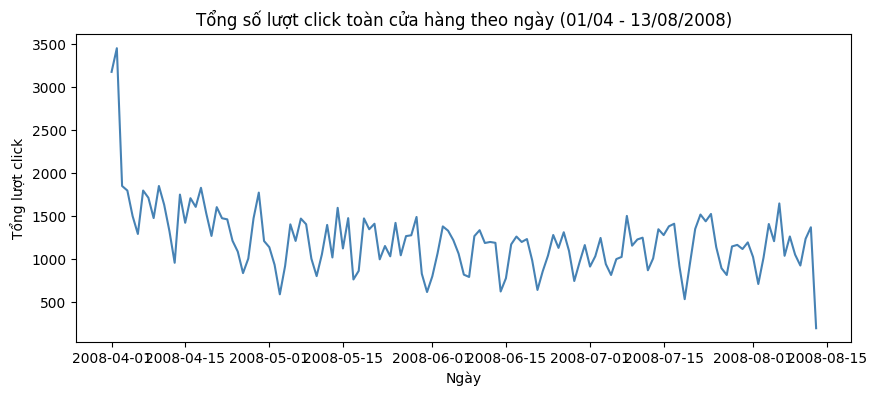

Trung vị số click mỗi ngày: 1203.0

Số lượt click trong 5 ngày cuối cùng:
date
2008-08-09    1056
2008-08-10     929
2008-08-11    1240
2008-08-12    1374
2008-08-13     200
dtype: int64


In [58]:
daily_total = df.groupby('date').size()

plt.figure(figsize=(10, 4))
plt.plot(daily_total.index, daily_total.values, color='steelblue')
plt.title('Tổng số lượt click toàn cửa hàng theo ngày (01/04 - 13/08/2008)')
plt.xlabel('Ngày')
plt.ylabel('Tổng lượt click')
plt.show()

print('Trung vị số click mỗi ngày:', daily_total.median())
print('\nSố lượt click trong 5 ngày cuối cùng:')
print(daily_total.tail(5))

**Phát hiện bất thường 1:** Ngày cuối cùng (`2008-08-13`) chỉ có **200 lượt click**, bằng khoảng 17% mức trung vị (~1.200 click/ngày). Đây là ngày cuối của file log, nên khả năng cao hệ thống dừng ghi log giữa ngày. Giữ ngày này sẽ làm sai việc đánh giá mô hình, nên nhóm loại bỏ ngày `2008-08-13`.

In [59]:
df = df[df['date'] < '2008-08-13'].copy()
print('Số dòng còn lại sau khi loại bỏ ngày 13/08:', len(df))

Số dòng còn lại sau khi loại bỏ ngày 13/08: 165274


**Kiểm tra tính nhất quán của sản phẩm:** Theo tài liệu mô tả, cửa hàng có **217 mã sản phẩm**. Nhóm kiểm tra xem trong suốt 5 tháng, mỗi sản phẩm có giữ cố định các thuộc tính hay không.

In [60]:
for col in ['category', 'colour', 'location', 'photo', 'price', 'price2', 'page']:
    check = df.groupby('product')[col].nunique()
    print(f'Số sản phẩm có nhiều hơn 1 giá trị ở cột {col}: {(check > 1).sum()}')

Số sản phẩm có nhiều hơn 1 giá trị ở cột category: 1
Số sản phẩm có nhiều hơn 1 giá trị ở cột colour: 0
Số sản phẩm có nhiều hơn 1 giá trị ở cột location: 0
Số sản phẩm có nhiều hơn 1 giá trị ở cột photo: 0
Số sản phẩm có nhiều hơn 1 giá trị ở cột price: 0
Số sản phẩm có nhiều hơn 1 giá trị ở cột price2: 0
Số sản phẩm có nhiều hơn 1 giá trị ở cột page: 0


**Phát hiện bất thường 2:** Mọi thuộc tính đều cố định, **riêng cột `category` có 1 sản phẩm** xuất hiện ở 2 danh mục. Nhóm tìm sản phẩm đó.

In [61]:
cat_per_prod = df.groupby('product')['category'].nunique()
print('Sản phẩm bị ghi vào nhiều danh mục:')
print(cat_per_prod[cat_per_prod > 1])

print('\nSố lần xuất hiện của mã A18 ở từng danh mục:')
print(df[df['product'] == 'A18']['category'].value_counts())

Sản phẩm bị ghi vào nhiều danh mục:
product
A18    2
Name: category, dtype: int64

Số lần xuất hiện của mã A18 ở từng danh mục:
category
1    935
2      1
Name: count, dtype: int64


A18 có 935 click ở danh mục 1 và chỉ 1 click ở danh mục 2. Để chắc chắn danh mục đúng, nhóm kiểm tra **chữ cái đầu của mã sản phẩm** có khớp với danh mục không.

In [62]:
pd.crosstab(df['product'].str[0], df['category'])

category,1,2,3,4
product,,,,
A,49685,1,0,0
B,0,38378,0,0
C,0,0,38537,0
P,0,0,0,38673


**Nhận xét:** Mã bắt đầu bằng `A` → danh mục 1 (Trousers), `B` → 2 (Skirts), `C` → 3 (Blouses), `P` → 4 (Sale). Chỉ có đúng 1 dòng lệch quy luật (chính là click lỗi của A18) → nhóm sửa A18 về danh mục 1.

In [63]:
df.loc[df['product'] == 'A18', 'category'] = 1
print('Số sản phẩm lỗi sau khi sửa:', (df.groupby('product')['category'].nunique() > 1).sum())

Số sản phẩm lỗi sau khi sửa: 0


---
## PHẦN 3: VÌ SAO CÁCH LÀM PHỔ BIẾN TRÊN MẠNG (DỰ ĐOÁN `PRICE2`) KHÔNG CÓ GIÁ TRỊ THỰC TẾ
Nhiều bài làm trên Kaggle/GitHub dùng tập dữ liệu này để phân loại cột `price2` (giá có cao hơn trung bình danh mục không) trên từng lượt click. Nhóm chạy 3 thử nghiệm để kiểm tra.

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

y_click = (df['price2'] == 1).astype(int)

# Thử nghiệm 1: Giữ cột 'price' trong tập đầu vào X
X_with_price = df[['category', 'colour', 'location', 'photo', 'price', 'page']]
X_tr1, X_te1, y_tr1, y_te1 = train_test_split(X_with_price, y_click, test_size=0.2, random_state=42)
dt1 = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_tr1, y_tr1)
print('1. Dự đoán price2 (giữ cột price) -> Accuracy:', round(accuracy_score(y_te1, dt1.predict(X_te1))*100, 2), '%')

# Thử nghiệm 2: Bỏ cột 'price', chia train_test_split ngẫu nhiên theo dòng click
X_no_price = df[['category', 'colour', 'location', 'photo', 'page']]
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X_no_price, y_click, test_size=0.2, random_state=42)
dt2 = DecisionTreeClassifier(random_state=42).fit(X_tr2, y_tr2)
print('2. Dự đoán price2 (bỏ price, chia ngẫu nhiên) -> Accuracy:', round(accuracy_score(y_te2, dt2.predict(X_te2))*100, 2), '%')

1. Dự đoán price2 (giữ cột price) -> Accuracy: 100.0 %
2. Dự đoán price2 (bỏ price, chia ngẫu nhiên) -> Accuracy: 92.91 %


**Thử nghiệm 3:** Nếu mô hình thật sự "hiểu" thì nó phải đoán được `price2` cho **sản phẩm chưa từng thấy**. Nhóm chia 217 sản phẩm thành 5 nhóm (lấy xen kẽ theo thứ tự chữ cái bằng `products[i::5]`). Mỗi lần giấu hẳn 1 nhóm sản phẩm để kiểm tra và chỉ học trên 4 nhóm còn lại.

In [65]:
products = sorted(df['product'].unique())         # danh sách 217 mã sản phẩm, xếp theo thứ tự chữ cái
accuracies = []

for i in range(5):
    test_products = products[i::5]                # lấy 1/5 số sản phẩm làm nhóm kiểm tra
    is_test = df['product'].isin(test_products)   # True nếu dòng thuộc sản phẩm kiểm tra
    dt3 = DecisionTreeClassifier(random_state=42)
    dt3.fit(X_no_price[~is_test], y_click[~is_test])            # học trên các sản phẩm còn lại
    acc = accuracy_score(y_click[is_test], dt3.predict(X_no_price[is_test]))
    accuracies.append(acc)
    print('Lần', i + 1, '- số sản phẩm kiểm tra:', len(test_products), '- Accuracy:', round(acc * 100, 1), '%')

print('3. Accuracy trung bình với SẢN PHẨM MỚI:', round(np.mean(accuracies) * 100, 1), '%')
print('   Mốc "luôn đoán lớp phổ biến nhất":', round(max(y_click.mean(), 1 - y_click.mean()) * 100, 1), '%')

Lần 1 - số sản phẩm kiểm tra: 44 - Accuracy: 27.1 %
Lần 2 - số sản phẩm kiểm tra: 44 - Accuracy: 45.1 %
Lần 3 - số sản phẩm kiểm tra: 43 - Accuracy: 46.4 %
Lần 4 - số sản phẩm kiểm tra: 43 - Accuracy: 43.9 %
Lần 5 - số sản phẩm kiểm tra: 43 - Accuracy: 57.8 %
3. Accuracy trung bình với SẢN PHẨM MỚI: 44.1 %
   Mốc "luôn đoán lớp phổ biến nhất": 51.2 %


**Kết luận từ thực nghiệm:**
1. Giữ `price` → **100%**, vì `price2` được tính trực tiếp từ `price` (giá > giá trung bình danh mục). Đây là **target leakage**: đầu vào chứa sẵn đáp án.
2. Bỏ `price` nhưng chia ngẫu nhiên → **~93%**, vì cả cửa hàng chỉ có 217 sản phẩm với thuộc tính cố định. Cùng một sản phẩm nằm ở cả Train và Test, nên mô hình chỉ **học thuộc** bảng 217 sản phẩm.
3. Với sản phẩm mới → **~44%**, còn thấp hơn cả mốc "luôn đoán lớp phổ biến nhất" (~51%). Điểm cao ở thử nghiệm 2 là ảo.
4. Ngoài ra, giá của sản phẩm cửa hàng đã biết sẵn, nên dự đoán `price2` không giúp được quyết định kinh doanh nào.

**Bài toán của nhóm:** Dự báo **số lượt xem của từng sản phẩm trong ngày mai**, chỉ dùng thông tin đến hết hôm nay → hỗ trợ **vận hành hằng ngày**: chọn sản phẩm nổi bật, phân bổ quảng cáo, theo dõi sản phẩm đang tăng/giảm độ quan tâm. (Việc nhập hàng cần dự báo xa hơn, ví dụ tổng 7 ngày tới — nhóm để ở hướng cải thiện.) Đây là bài toán **hồi quy (regression)** có yếu tố **chuỗi thời gian**.

**Nhóm đã cân nhắc nhiều cách đặt bài toán trước khi chọn:**

| Cách đặt bài toán | Quyết định | Lý do |
|---|---|---|
| Phân loại `price2` cho từng click | Loại | Leakage / học thuộc, không có giá trị kinh doanh (3 thử nghiệm ở trên) |
| **Hồi quy: lượt xem ngày mai của từng sản phẩm** | **Chọn làm bài chính** | Đầu ra là con số, chứa nhiều thông tin nhất, dùng được cho nhiều quyết định |
| Phân loại: ngày mai sản phẩm có được "quan tâm cao" không | Làm thêm ở Phần 9 để so sánh | Câu hỏi có/không dễ dùng cho việc chọn sản phẩm nổi bật; cho phép dùng Logistic Regression và Naive Bayes |
| Mỗi sản phẩm một mô hình riêng | Không chọn | Mỗi sản phẩm chỉ có ~100 ngày dữ liệu; một mô hình chung học được quy luật chung từ cả 217 sản phẩm |
| Dự báo theo từng phiên truy cập / quốc gia | Không chọn | Quyết định kinh doanh được đưa ra theo sản phẩm và theo ngày; ~80% click đến từ Ba Lan nên chia theo quốc gia rất thưa |

**Chọn thuật toán nào trong các thuật toán đã học?**

| Thuật toán đã học | Dùng cho | Có phù hợp với bài chính (hồi quy)? | Dùng ở đâu |
|---|---|---|---|
| Linear Regression | Hồi quy | Có — mô hình nền, dễ giải thích | Phần 6 |
| Ridge (Linear Regression có phạt) | Hồi quy | Có — kiểm tra đa cộng tuyến giữa các cột trung bình | Phần 6 |
| KNN | Hồi quy và phân loại | Có (`KNeighborsRegressor`) — nhưng nhạy với cột không liên quan, cần chọn đặc trưng | Phần 6, Phần 9 |
| Decision Tree | Hồi quy và phân loại | Có — bắt được quan hệ phi tuyến | Phần 6, Phần 9 |
| Random Forest | Hồi quy và phân loại | Có — trung bình nhiều cây, ổn định hơn một cây | Phần 6, Phần 9 |
| Logistic Regression | **Chỉ phân loại** | Không — đầu ra là xác suất của một nhãn, không phải số lượt xem | Phần 9 |
| Naive Bayes | **Chỉ phân loại** | Không — cũng chỉ dự đoán nhãn | Phần 9 |
